# Example in `R`
We have covered a lot of information by this point. Although this may give the impression that binary logistic regression is very complex, we will now see that its application is actually quite simple in practice. This is in part due to the support of many familiar functions within `R`, making this a reasonably straightforward extension of the normal linear model. 

## Packages
We will first load all the packages we need. Because some of these are a bit "chatty" when we load them, we suppress all the startup messages using the `suppressMessages()` function.

In [1]:
library('datarium')
library('gridExtra')
suppressMessages(library('effects'))
suppressMessages(library('car'))
suppressMessages(library('emmeans'))

## The `heartdisease` Dataset
The dataset we will use as our example comes from the `datarium` package and is called `heartdisease`. It contains clinical and demographic data on diagnosis of coronary artery disease in 920 patients across four different sites. To keep things simple, we will subset the data to only the `cleveland` site. Our basic model for this analysis will then involve the following variables:

- **disease**: binary outcome of the presence (`1`) or absence (`0`) of heart disease. This is derived from the original variable `num`.
- **age**: the subject's age.
- **sex**: a two level factor coded as:
    - `0` = *female* 
    - `1` = *male*.
- **cp**: a four level factor categorising any chest pain the subject has been experiencing. This is coded as:
    - `1` = *typical angina* 
    - `2` = *atypical angina*
    - `3` = *non-anginal pain* 
    - `4` = *asymptomatic*

These variables are not labelled very clearly, particularly the factor levels, so we will adjust these so that the `R` output is more intuitive. We can therefore subset and relabel the variables we need using

In [2]:
data('heartdisease')

tmp       <- subset(heartdisease, dataset == "cleveland")
cleveland <- data.frame("disease" = as.integer(tmp$num > 0),
                        "age"     = tmp$age,
                        "sex"     = tmp$sex,
                        "cpain"   = tmp$cp
)

cleveland$sex[cleveland$sex == 0] <- "female"
cleveland$sex[cleveland$sex == 1] <- "male"

cleveland$cpain[cleveland$cpain == 1] <- "tAng"
cleveland$cpain[cleveland$cpain == 2] <- "aAng"
cleveland$cpain[cleveland$cpain == 3] <- "nAng"
cleveland$cpain[cleveland$cpain == 4] <- "asymp"

cleveland$sex   <- as.factor(cleveland$sex)
cleveland$cpain <- relevel(as.factor(cleveland$cpain), ref='asymp')

head(cleveland)

  disease age    sex cpain
1       0  63   male  tAng
2       1  67   male asymp
3       1  67   male asymp
4       0  37   male  nAng
5       0  41 female  aAng
6       0  56   male  aAng

We have therefore created a new dataset containing only the variables we need, with both `sex` and `cp` (renamed to `cpain`) containing more intuitive labels, and with the baseline chest pain category set to *asymptomatic*. We can check the format of each variable to make sure that all the changes have taken effect as we would expect

In [3]:
str(cleveland)

'data.frame':	303 obs. of  4 variables:
 $ disease: int  0 1 1 0 0 0 1 0 1 1 ...
 $ age    : num  63 67 67 37 41 56 62 57 63 53 ...
 $ sex    : Factor w/ 2 levels "female","male": 2 2 2 2 1 2 1 1 2 2 ...
 $ cpain  : Factor w/ 4 levels "asymp","aAng",..: 4 1 1 3 2 2 1 1 1 1 ...


and can produce some basic summaries to help understand the dataset

In [4]:
summary(cleveland)

    disease            age            sex        cpain    
 Min.   :0.0000   Min.   :29.00   female: 97   asymp:144  
 1st Qu.:0.0000   1st Qu.:48.00   male  :206   aAng : 50  
 Median :0.0000   Median :56.00                nAng : 86  
 Mean   :0.4587   Mean   :54.44                tAng : 23  
 3rd Qu.:1.0000   3rd Qu.:61.00                           
 Max.   :1.0000   Max.   :77.00                           

## Fitting the Model
We now turn to fitting the model in `R`. We start with a formal description and then see how this manifests in `R`.


### Model Description
Our model is quite simple in principle, as we are trying to assess the relationship between the probability of heart disease and the variables `age`, `sex` and `cpain`. As `age` is a continuous variable, it can enter the model as-is. Because `sex` is categorical, it will need to enter as dummy variables and will require $k - 1 = 2 - 1 = 1$ dummy variable to represent it. Because `cpain` is also categorical, it will also need to enter as dummy variables and will require $k - 1 = 4 - 1 = 3$ dummy variables to represent it. To keep things simple, we will not consider any interactions. On the scale of the link function, the model is therefore:

$$
\begin{align*}
    \log\left(\frac{\pi_{i}}{1 - \pi_{i}}\right) =&~\beta_{0} + \left(\beta_{1} \times \text{age}_{i}\right) + \left(\beta_{2} \times \text{SEX}_{i}\right) + \\ 
    &\left(\beta_{3} \times \text{CPAIN1}_{i}\right) + \left(\beta_{4} \times \text{CPAIN2}_{i}\right) + \left(\beta_{5} \times \text{CPAIN3}_{i}\right)
\end{align*}
$$

where $\text{age}$ is the continuous variable of age, $\text{SEX}$ is the single dummy variable associated with sex and $\text{CPAIN1}$, $\text{CPAIN2}$ and $\text{CPAIN3}$ are the three dummy variables associated with the chest pain categories. We can define these more explicitly as

$$
\text{SEX}_{i} = 
    \begin{cases}
        1, & \text{if subject $i$ is \textit{male}}, \\
        0, & \text{if subject $i$ is \textit{female}}.
    \end{cases}
$$

and

$$
\begin{align*}
    \text{CPAIN1}_{i} &= 
    \begin{cases}
        1, & \text{if subject $i$ has \textit{atypical} angina pain},\\
        0, & \text{otherwise}.
    \end{cases} \\
    \text{CPAIN2}_{i} &= 
    \begin{cases}
        1, & \text{if subject $i$ has \textit{non-angina} pain},\\
        0, & \text{otherwise}.
    \end{cases} \\
    \text{CPAIN3}_{i} &= 
    \begin{cases}
        1, & \text{if subject $i$ has \textit{typical} angina pain},\\
        0, & \text{otherwise}.
    \end{cases}
\end{align*}
$$

Here, we have used *asymptomatic* as the baseline category, given that is what we have set in `R`.

### Specifying the Model in `R`
Next, we specify the model in `R`. Before doing so, we should check how `sex` and `cpain` are coded. For `sex` we have

In [5]:
contrasts(cleveland$sex)

       male
female    0
male      1

indicating that `female` is the baseline category. As such, this coefficient will represent the difference between the baseline of `female` and `male`. For `cpain` we have

In [6]:
contrasts(cleveland$cpain)

      aAng nAng tAng
asymp    0    0    0
aAng     1    0    0
nAng     0    1    0
tAng     0    0    1

indicating that `asymp` is the baseline category and that each of the 3 dummy variables will represent comparisons against `asymp`.

In order to fit the model, we use the `glm` function included with base `R`. This has a syntax identical to `lm` and so should feel very familiar. The only additional option we need to provide is `family`, which indicates the specific form of the exponential family that we want to use. For logistic regression, this is `binomial`, remembering that the Bernoulli distribution is a special case of the binomial. We can also specify the link function we want to use as an additional argument to the named distribution. In this case we want to use the logit link, leading to the full argument `family=binomial(link=logit)`.

In [7]:
mod <- glm(disease ~ age + sex + cpain, # model formula
           family=binomial(link=logit), # binomial family w/logit link
           data=cleveland)              # dataset

Much like the `lm` function, we can then call `summary()` on the model object to print a table of the estimates, hypothesis tests and other details about the model fit

In [8]:
summary(mod)


Call:
glm(formula = disease ~ age + sex + cpain, family = binomial(link = logit), 
    data = cleveland)

Coefficients:
            Estimate Std. Error z value Pr(>|z|)    
(Intercept) -3.80663    1.05903  -3.594 0.000325 ***
age          0.06661    0.01767   3.770 0.000163 ***
sexmale      1.71946    0.34332   5.008 5.49e-07 ***
cpainaAng   -2.52568    0.44477  -5.679 1.36e-08 ***
cpainnAng   -2.37697    0.35425  -6.710 1.95e-11 ***
cpaintAng   -2.27264    0.53230  -4.269 1.96e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 417.98  on 302  degrees of freedom
Residual deviance: 293.87  on 297  degrees of freedom
AIC: 305.87

Number of Fisher Scoring iterations: 5


Many of the different topics we have been discussing are summarised in this table. Firstly, note that the bottom of the table says `Number of Fisher Scoring iterations: 5`. This indicates the number of iterations that were needed during maximum likelihood estimation to reach convergence. 

Above this are reports of deviance, as analogous to the model variance under the standard linear model. `R` will report two different deviance measures. The `Residual deviance` is the deviance associated with the current model and can be taken as akin to the residual variance. This indicates how well the current model fits, but is not on a very understandable scale. To help interpret this, `R` also reports the `Null deviance`, which is the deviance associated with a model that only contains an intercept. The closer these two metrics are in value, the less of an improvement out current model makes over a model that just contains a constant and nothing else. 

Above this is a message saying `(Dispersion parameter for binomial family taken to be 1)`, which should be understandable from our previous discussions because the variance function for the binomial involves setting $\phi = 1$.

Finally, the table of coefficients should be very familiar from calling `summary()` on a model from `lm`. The key differences here are that the *scale* of the estimates is the log-odds of having heart disease, and that the tests on the coefficients are asymptotic Wald $z$-tests, rather than $t$-tests.

### Interpreting the Estimates
Before getting to inference, it is important that we understand how to interpret the estimates from the coefficients table. This involves applying the guidance given previously about what the estimates mean, alongside some manual transformations of their values. 

Beginning with the intercept, we know from our previous discussion that this relates to setting all other predictors to 0. For `age`, this means an age of 0, for `sex` this means female and for `cpain` this means asymptomatic. The intercept is therefore the predicted log-odds of having heart disease if you are female, have no chest pains and are aged 0. Clearly, this is not particularly useful. We could make it more useful by mean-centering `age` so that the intercept represents the *average* age in the sample, but we will leave this to one side as it does not matter particularly. 

We could convert this to a probability using the `plogis` function, which is `R`'s version of the inverse-logit

In [9]:
beta.0 <- coef(mod)[1]
plogis(beta.0)

(Intercept) 
  0.0217398 

but, given how unhelpful the interpretation is, this is of little value, especially as the probability is very close to 0. 

In terms of the remaining effects, it is more helpful to undo the log and interpret the values as odds-ratios. We can do this using

In [10]:
beta <- coef(mod)[2:6]
exp(beta)

       age    sexmale  cpainaAng  cpainnAng  cpaintAng 
1.06887922 5.58149903 0.08000403 0.09283154 0.10303956 

We could also turn these into percentage changes in the odds using

In [11]:
(exp(beta) - 1)*100

       age    sexmale  cpainaAng  cpainnAng  cpaintAng 
  6.887922 458.149903 -91.999597 -90.716846 -89.696044 

This gives some very large values for some of the effects. For instance, the effect of `sex` is associated with around a 460% increase in the odds. This sounds dramatic, but remember that these are changes in the odds, *not* probability. As the odds-ratio for `sex` is around 5.6, that indicates that the odds of having heart disease is around 5.6 times higher for males than the odds of having heart disease for females. This equates to a percentage change of $(5.6 - 1) \times 100 = 460\%$, which sounds much bigger than 5.6. Also, remember that the practical implications of these percentage changes depend upon the baseline odds. A number may well increase by 460%, but if it was small to begin with it will still be small afterwards. 


:::{note} Absolute vs Relative Risk
These interpretational nuances illustrate a broader lesson about interpreting *absolute* versus *relative* risk. In the news, you often hear phrases such as "eating this food doubles the risk of cancer". However, it's difficult to judge the practical significance of this claim without knowing what the baseline risk actually is. There's a big difference between doubling a baseline probability of 0.02% and a baseline probability of 40%. Consequently, when interpreting claims about relative risk, we should always consider the absolute risk as well. A large relative increase in risk doesn't necessarily imply a large absolute increase in the probability of an outcome.
:::

The `effects` package can be invaluable for helping make sense of these various effects. We have previously used this package to create plots, which we will also do further below. However, for GLMs, looking at the actual values returned prior to plotting can be very helpful. In general, `effects` will automatically try to express the results on the most intuitive scale. As such, the default for logistic regression is *probability*. If we extract the effects, we can therefore view the probabilities using

In [12]:
effs <- allEffects(mod)
print(effs)

 model: disease ~ age + sex + cpain

 age effect
age
       30        40        50        60        80 
0.1297413 0.2249339 0.3609979 0.5237498 0.8064777 

 sex effect
sex
   female      male 
0.1908713 0.5683442 

 cpain effect
cpain
    asymp      aAng      nAng      tAng 
0.7288085 0.1769584 0.1996661 0.2168605 


Here we can see the probabilities of heart disease associated with a selection of ages, showing a clear increase as age increases. We can also see that the probability is much lower for females than male. Finally, we can see that the highest probability is associated with those who have no chest pain, with the various types of angina showing similar and lower probabilities. Immediatley, this is easier than trying to understand the coefficients returned on either the odds or log-odds scale.

## Model Diagnostics
As mentioned in the previous section, there are assumptions that we need to check prior to inference. The `glm()` function does have a standard set of plots that can be produced by calling `plot()` on the model object.

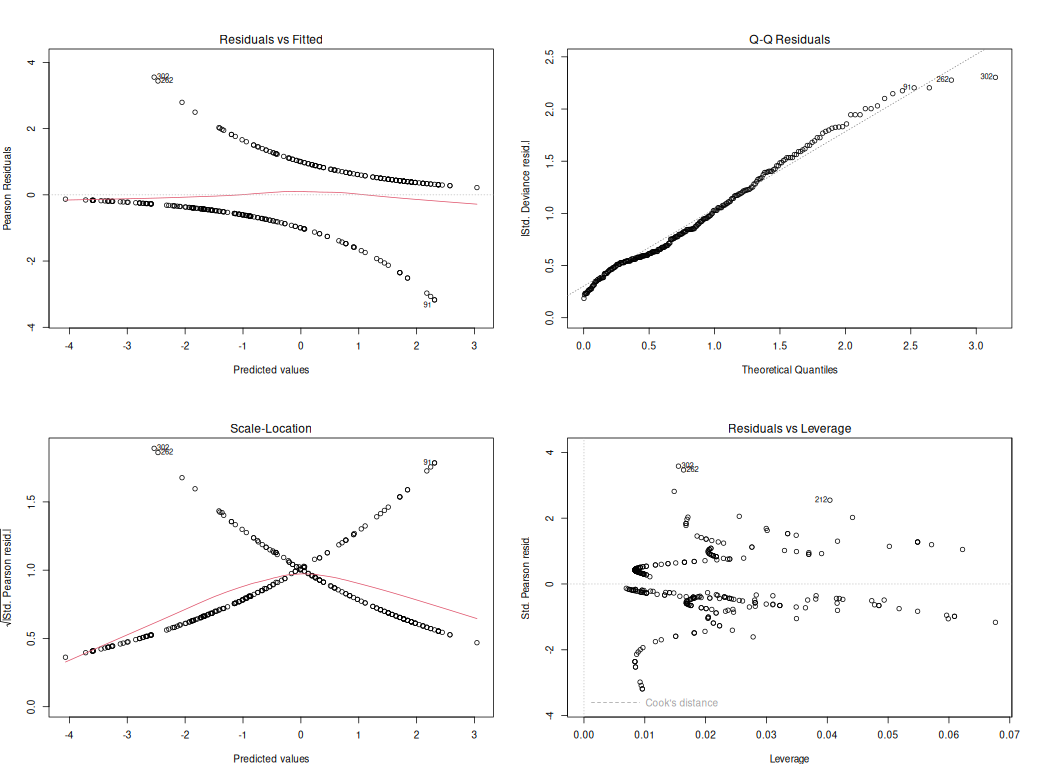

In [13]:
par(mfrow=c(2,2))
plot(mod)
par(mfrow=c(1,1))

However, for binary logistic regression, only one of these is useful. The rest are either irrelevant (such as checking the marginal distribution of the data) or misleading due to the binary nature of the outcome. This includes both the Residuals vs Fitted plot and the Scale-Location plot, which are difficult to interpret due to the stripes caused by the binary outcome. As such, only the Residuals vs Leverage plot is of use. Even then, we need to ignore the strange shapes in the plot and only focus on those observations with both high leverage and a high standardised residual. `R` will plot isocontour lines associated with Cook's Distance > 0.5 and > 1. As these are not visible on the plot above, there are no data points of particular concern.

As an alternative to plotting several visualisations that we will subsequently ignore, we can request one of the *hidden* assumptions plots that only shows Cook's Distance.

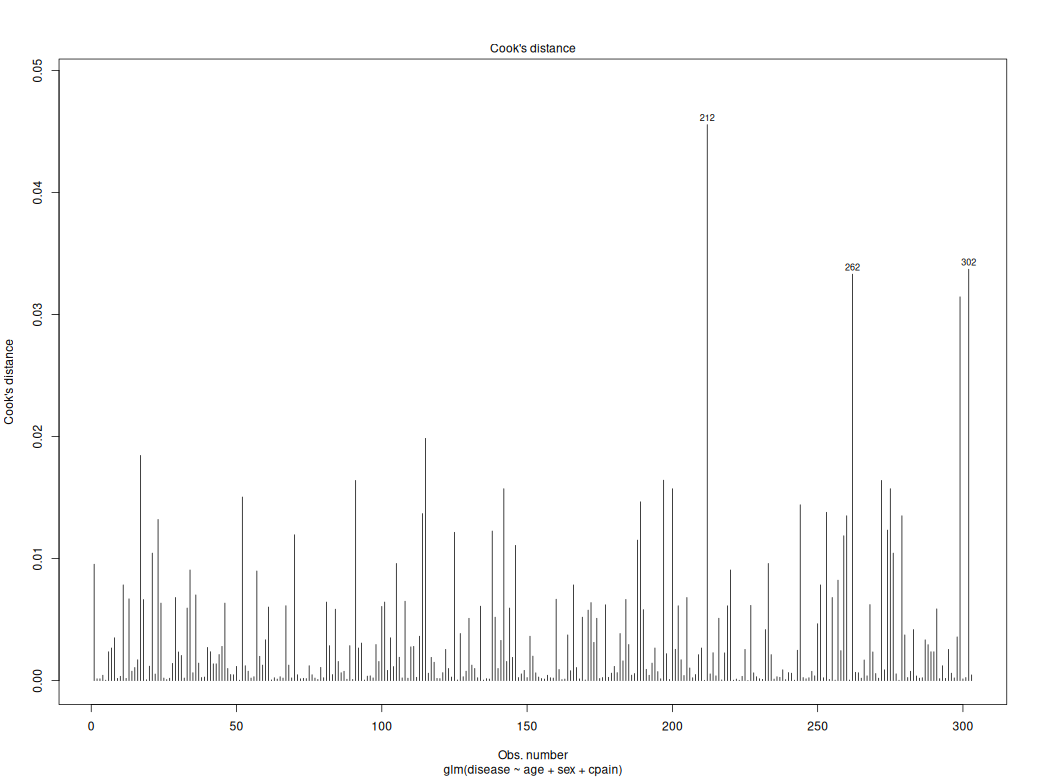

In [14]:
plot(mod,which=4)

Here we can see that no values exceed 0.5 or 1 and thus there are no highly-influential points in this example.

### Plotting the Model Fit
A much more important aspect of binary linear regression is assessing the quality of the model fit. This needs to be judged on the scale of the link function, because this is where the standard linear regression equation is found. Any evidence that a simple straight line is insufficient will require transforms or additional non-linear modelling elements on this scale.

We can again make use of the `effects` package to assess the model fit

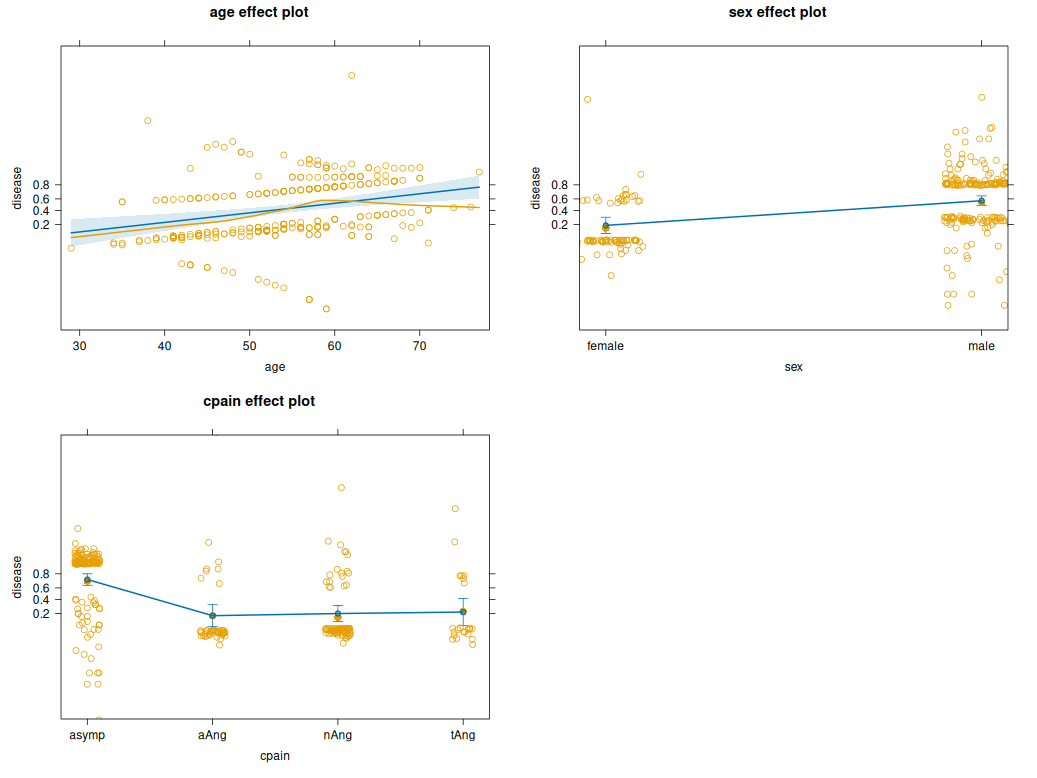

In [15]:
plot(allEffects(mod, partial.residuals=TRUE))

The most important aspect here is that an addition LOESS smoothing line is added tracing the average pattern through the residuals. This is shown in yellow and should roughly agree with the shape of the model fit shown in blue. This is more relevant for continuous predictors than categorical predictors. As such, the model fit for `age` should be our key focus here. We can isolate this using 

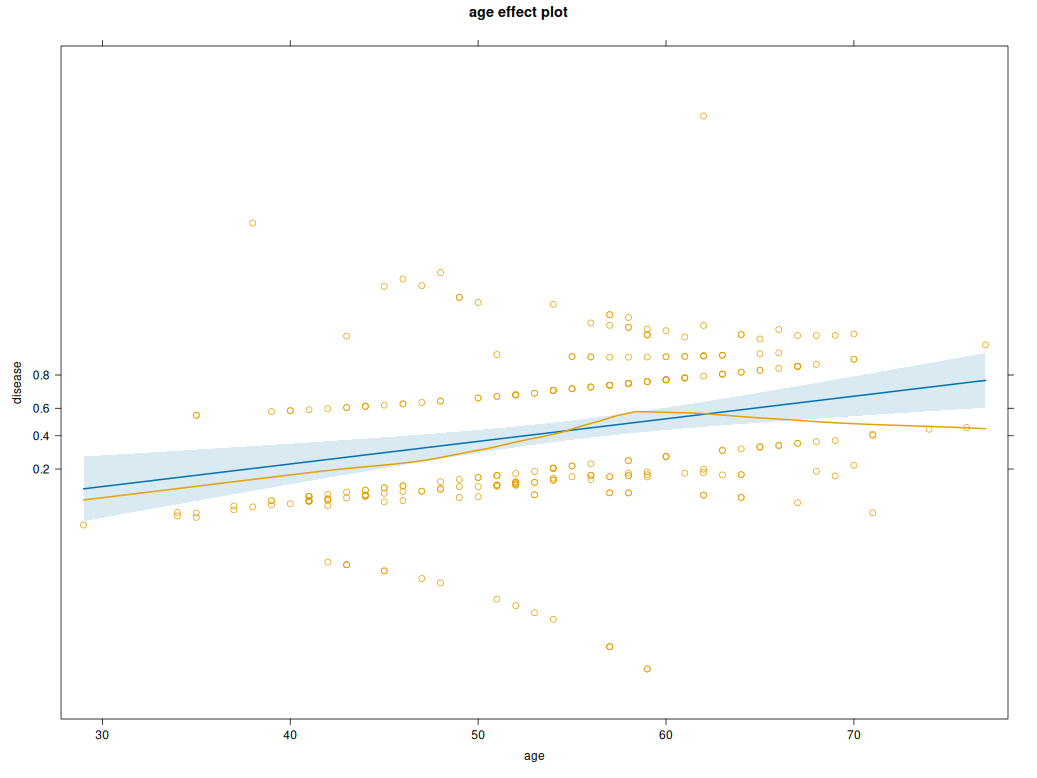

In [16]:
plot(effect('age', mod, partial.residuals=TRUE))

This plot is drawn on the scale of the log-odds, but with probability labels added. As such, the fit is a straight line, even though the $y$-axis reports probabilities. We can see here that the LOESS line shows a small bump and then a decrease towards later values of `age`. This is not particularly severe and could be explained by the fact that there are fewer individuals with heart disease at greater values of `age`, simply because those with heart disease die younger. This could therefore be a form of survivorship bias. 

As an example, if we thought it was worth it, we could model a slightly different shape. For instance, a quadratic effect of `age` would look like this

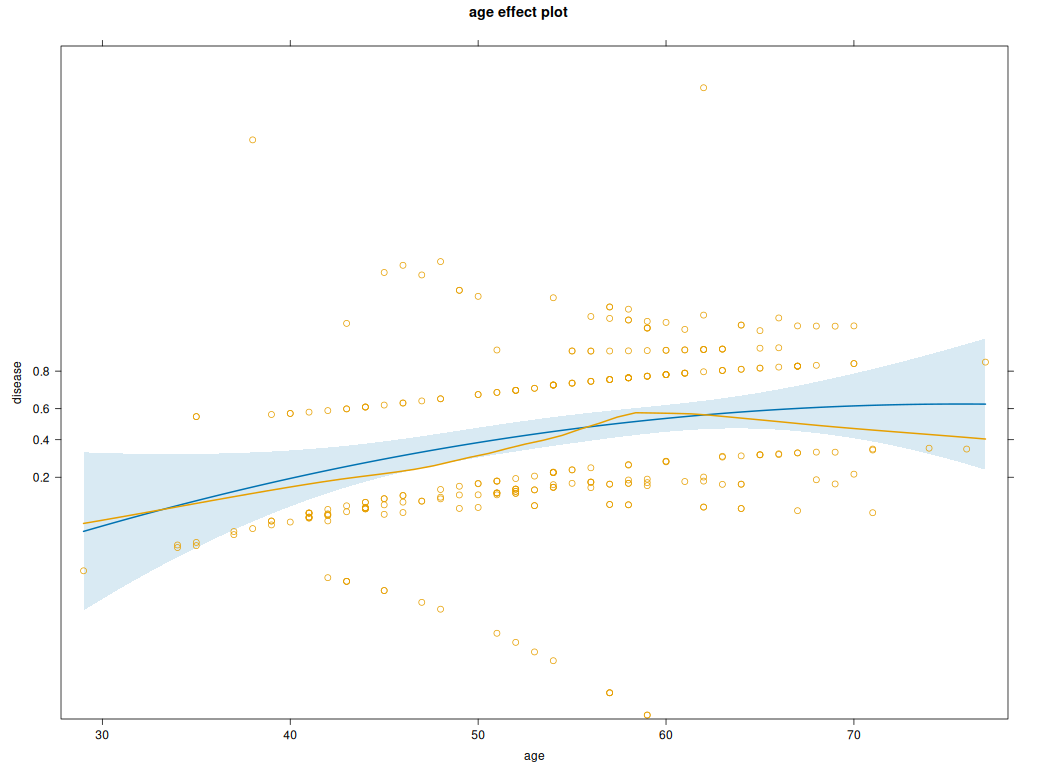

In [17]:
mod.quad <- glm(disease ~ poly(age,2) + sex + cpain, # model formula
                family=binomial(link=logit),         # binomial family w/logit link
                data=cleveland)                      # dataset

plot(effect('poly(age,2)', mod.quad, partial.residuals=TRUE))

and thus captures a subtle non-linear effect of `age`, suggesting that the probability flattens as `age` increases.

#### Options for Scaling Effects Displays
The `effects` package has several options for how the plots are scaled, depending upon how you want to interpret them. These are compared below in terms of the `age` effect from our original model.


In [ ]:
# extract age effect
age.eff <- effect('age',mod)

# compare plots
p1 <- plot(age.eff, axes=list(y=list(type="rescale" ))) # link scale w/prob labels
p2 <- plot(age.eff, axes=list(y=list(type="link"    ))) # link scale
p3 <- plot(age.eff, axes=list(y=list(type="response"))) # probability scale

grid.arrange(p1, p2, p3, ncol=3)

The left plot is the default and uses the option `type="rescale"`. This will draw the $y$-axis using the log-odds scale so that the fit is linear. However, to make this easier to interpret, probability labels will be written instead. For instance, a probability of 0.2 is equivalent to a log-odds of −1.386. So the plot places the label "0.2" at the location "-1.386" on the $y$-axis. Notice that the gap between 0.4 and 0.6 is not the same as the gap between 0.6 and 0.8. So the model fit is not linear on the probability scale.

The middle plot uses the option `type="link"`, and will do exactly the same as above, but *without* the probability labels. As such, this is a direct plot of the model fit on the scale of the link function, meaning the $y$-axis is given in units of the log-odds.

The right plot uses the option `type="response"`, and will draw the model fit on the true probability scale after piping the model through the inverse link function. This means that the S-shaped curved typified by the logit link will be visible on the plot.

In general, `"rescale"` or `"response"` are the most practical, as these present the effects on an interpretable scale in terms of probability. The log-odds scale is not very intuitive and would generally be a poor choice for visualisation. As such, the difference is largely between whether you want to see the sigmoidal curves, or would rather interpret the effects in terms of the straight-line fit.

## Inference on the Effects
Once we are happy that there are no extreme values and that the model fit is acceptable, we can turn to inference. This is performed using the Wald tests on the coefficients, as well as the omnibus tests that typify an Analysis of Deviance. We will illustrate both below.

### Wald Tests

### Omnibus Tests

In [ ]:
Anova(mod)

We can easily demonstrate how these tests are equivalent to model comparisons by computing one of them using explicit model comparisons. For instance, to test the effect of `cp` we can specific a null model that does not contain `cp` and a full model that does contain `cp`.

In [ ]:
mod.0 <- glm(disease ~ age + sex,         family=binomial(link=logit), data=cleveland)
mod.1 <- glm(disease ~ age + sex + cpain, family=binomial(link=logit), data=cleveland)

We can then compare these using the `anova` function

In [ ]:
anova(mod.0,mod.1)

Notice that the `Df`, `Deviance` and $p$-value are all identical to the table from `Anova`, demonstrating that these results are indeed model comparisons.

### Follow-up Tests

## Conclusions